# 1. Find peaks and two lattice bases

Start here. This example reads an existing DM4 file, runs the original peak finder and automatic two-lattice selection, and saves the inputs for **02_fitting.ipynb**.

All coordinates and radii are in **binned image pixels**, ordered `(row, col)`. Algorithms live in `moire_cdw`; this notebook contains only settings and calls.

Use a Python environment with QuantEM and PyTorch installed. The first cell imports this checkout directly; no installation or environment changes are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Locate this checkout when launched from the project or an examples directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/moire_cdw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
import json
import quantem as em
from quantem.core.visualization import show_2d
from moire_cdw import DiffractionMoire

## Input and detection settings

In [2]:
DATA_FILE = ROOT / "data/Bi_1_total_0010.dm4"
BIN_FACTOR = 4
RANDOM_SEED = 0  # Reproducible RANSAC center search.
PEAK_SETTINGS = dict(refine_radius_px=3, sigma=2.5, threshold=2e3, min_distance_px=20)
INTENSITY_SETTINGS = dict(sigma=2.5, distance=8)
VECTOR_SETTINGS = dict(center_find_method="mean", center_distance=50)
MANUAL_INDICES = None  # Optional: [origin, u1, v1, u2, v2].
OUTPUT = ROOT / "outputs/two_lattice/detection.npz"
DISPLAY = dict(figsize=(8, 8), norm=dict(power=0.5, lower_quantile=0.4, upper_quantile=0.999))

## Read and bin the diffraction image

Shape: (4096, 4096) -> (1024, 1024)
Binned sampling: [0.01444064 0.01444064] Units: ['1/nm', '1/nm']


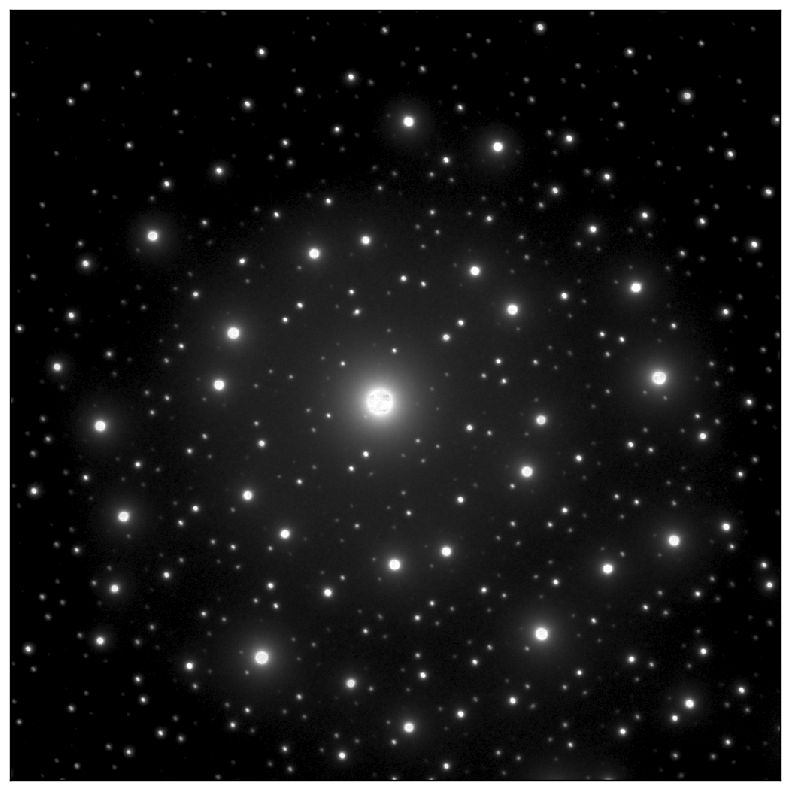

In [3]:
im = em.io.read_2d(str(DATA_FILE), file_type="digitalmicrograph")
im_bin = im.bin(BIN_FACTOR, reducer="mean")
print("Shape:", im.shape, "->", im_bin.shape)
print("Binned sampling:", im_bin.sampling, "Units:", im_bin.units)
show_2d(im_bin, **DISPLAY);

## Find peaks, then reorder by local intensity

`real_peaks_intensity_range` reorders the peaks by local maximum intensity. Select indices **after** this step; indices from an earlier ordering are no longer valid.

Detected peaks: 226


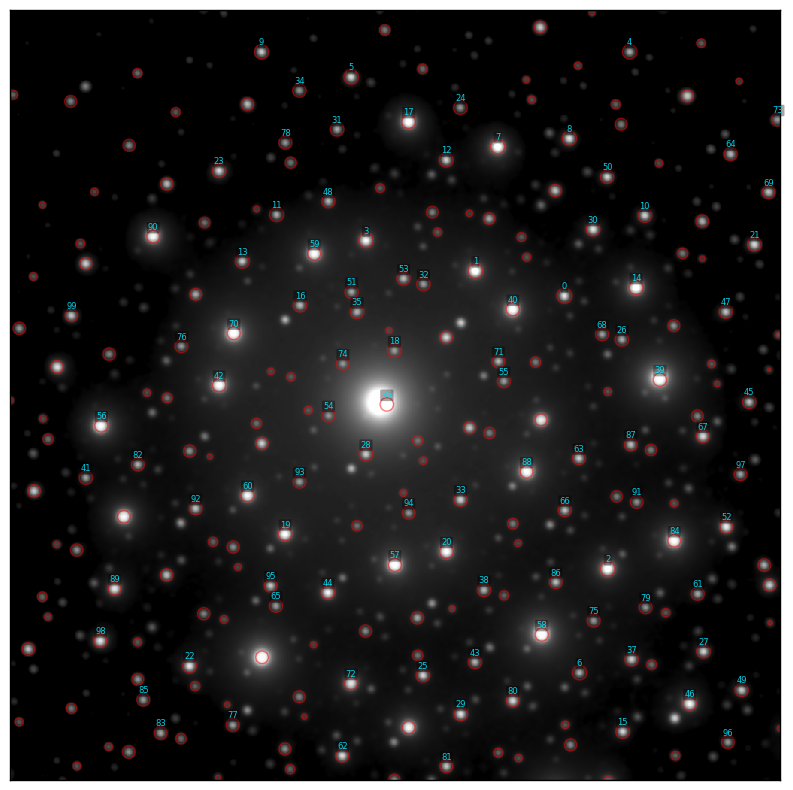

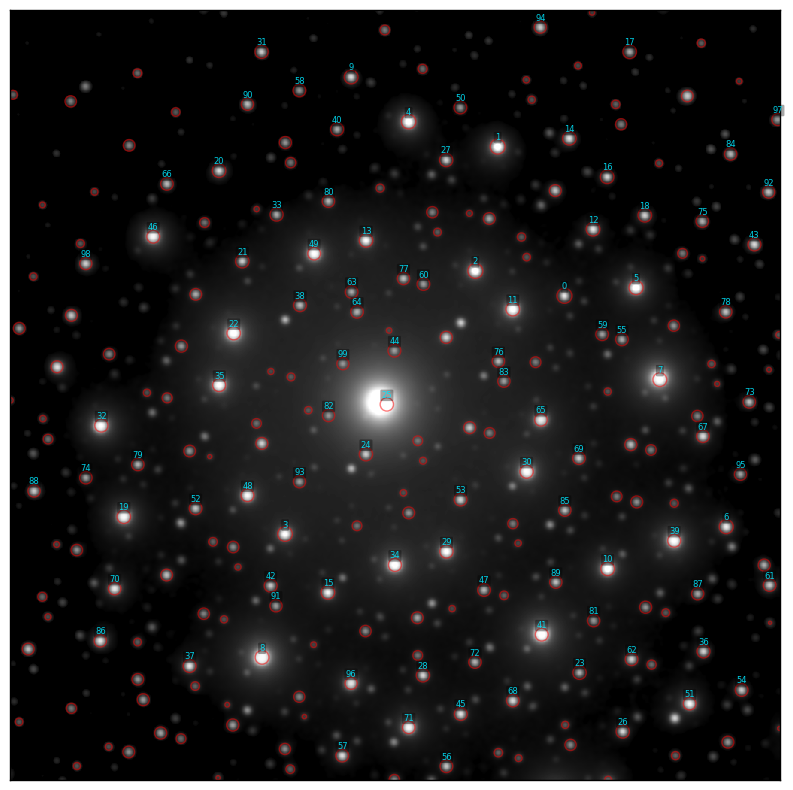

In [4]:
moire = DiffractionMoire.from_data(im_bin)
moire.find_peaks(**PEAK_SETTINGS, plot_labels=True, plot_label_top_k=100, **DISPLAY)
moire.real_peaks_intensity_range(**INTENSITY_SETTINGS, plot_labels=True,
                                 plot_label_top_k=100, **DISPLAY)
print("Detected peaks:", len(moire.peaks))

## Select two lattice bases

The original RANSAC center refinement and intensity-ranking rules are retained. Inspect the overlay before fitting. If automatic selection fails for another image, set `MANUAL_INDICES` above using the displayed labels and rerun this cell.

25


Result: find 148 symmetric point pairs, final center: [520.98148413 491.50232934]
27738
[[ 0  4]
 [ 0  6]
 [ 0  9]
 [ 0 10]]


[origin, u1, v1, u2, v2] = [25 35 63 22 49]


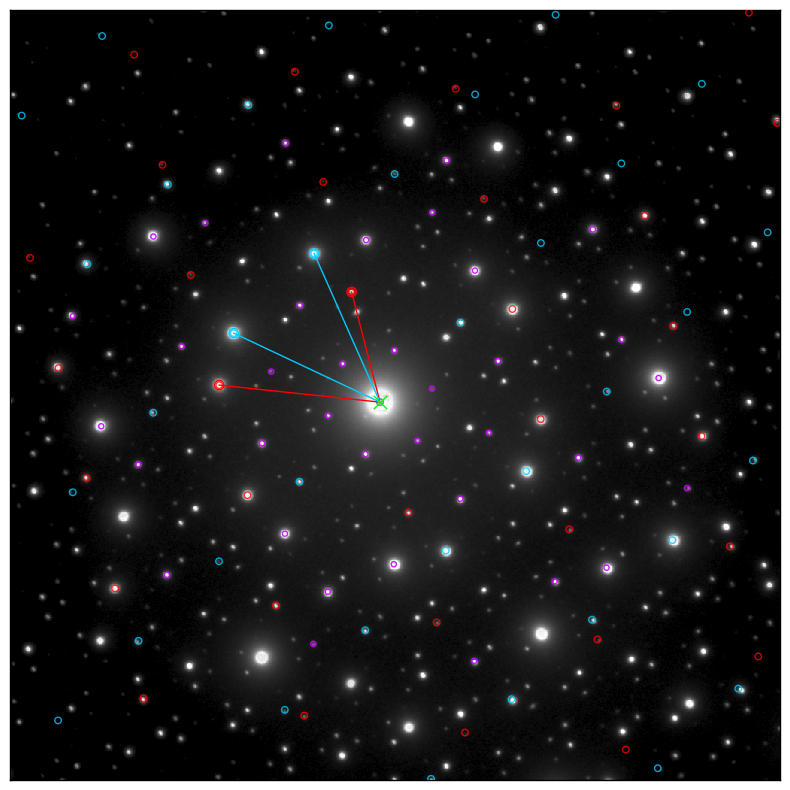

In [5]:
np.random.seed(RANDOM_SEED)
vector_indices = (moire.auto_find_lattice_vectors(**VECTOR_SETTINGS)
                  if MANUAL_INDICES is None else MANUAL_INDICES)
vector_indices = np.asarray(vector_indices, dtype=int)
print("[origin, u1, v1, u2, v2] =", vector_indices)
preview = moire.lattice_vectors(
    ind_origin=vector_indices[0], ind_u1=vector_indices[1], ind_v1=vector_indices[2],
    ind_u2=vector_indices[3], ind_v2=vector_indices[4], moire_draw=True,
    moire_parent_maxlen_px=250, return_peaks=True, **DISPLAY,
)

## Save the detection result

This stores the binned image, peak ordering, selected indices, and sampling together. Rerunning replaces this example output. Raw DM4 files are read only.

In [6]:
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
metadata = dict(source_file=str(DATA_FILE), bin_factor=BIN_FACTOR, random_seed=RANDOM_SEED,
                peak_settings=PEAK_SETTINGS, intensity_settings=INTENSITY_SETTINGS,
                vector_settings=VECTOR_SETTINGS, manual_indices=MANUAL_INDICES)
np.savez_compressed(OUTPUT, image=im_bin.array, peaks=moire.peaks, intensity=moire.I,
                    vector_indices=vector_indices, sampling=im_bin.sampling,
                    units=np.asarray(im_bin.units), metadata_json=json.dumps(metadata))
print("Saved:", OUTPUT)

Saved: /Users/hu/Project/Moire/Morie/Moire_CDW/outputs/two_lattice/detection.npz


Next: open **02_fitting.ipynb**. It reads the saved file in a fresh kernel.